# Лабораторная работа 6. Чёрный ящик и трансферируемость атак: transfer-based, score-based, decision-based методы

**Курс:** Машинное обучение. Безопасность ИИ-систем

**По материалам лекции 5**


**Среда:** Python, PyTorch, torchvision


## Цель работы
Закрепить методы построения adversarial-примеров в условиях ограниченного доступа к целевой модели и научиться сравнивать transfer-based, score-based и decision-based атаки по успешности, числу запросов и величине вносимого искажения.

## Результаты обучения
После выполнения работы вы должны уметь:
- обучать суррогатную модель через запросы к оракулу и переносить на неё белоящичную атаку (transfer-based);
- реализовывать оценку градиента через запросы confidence-баллов методом конечных разностей (ZOO) и методом случайной выборки (NES);
- реализовывать decision-based атаку (Boundary Attack), работающую только с итоговой меткой класса;
- сравнивать три класса чёрно-ящичных атак по критерию «качество атаки / стоимость запросов» и обосновывать выбор метода под конкретный сценарий доступа к API.

## Как пользоваться этим ноутбуком
- Ячейки с `# TODO` необходимо заполнить самостоятельно.
- Ячейки с текстом **"Вопрос для отчёта"** требуют письменного ответа в markdown-ячейке ниже.
- Перед сдачей: Kernel → Restart & Run All, ноутбук должен выполняться от начала до конца без ошибок.
- Все атаки в этой работе взаимодействуют с целевой моделью только через специальный объект-оракул — прямой доступ к её параметрам и градиентам запрещён по условию задания (это имитирует реальный чёрный ящик).


## 0. Подготовка окружения

In [1]:
# TODO: импортируйте необходимые библиотеки
# Подсказка: numpy, matplotlib, torch, torch.nn, torch.nn.functional,
# torchvision (datasets, transforms), torch.utils.data.DataLoader, pandas, time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import pandas as pd
import time
import random

RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")


Device: cpu


## Часть I. Целевая модель и оракул

**Задание:** загрузите MNIST, обучите CNN-классификатор (2 свёрточных слоя + полносвязный классификатор) — эта модель будет играть роль "чёрного ящика". Затем реализуйте класс-обёртку `QueryCounter`, через который ВСЕ последующие атаки должны обращаться к модели — прямой вызов `target_model(x)` в атаках запрещён, чтобы корректно считать число запросов.

In [2]:
# TODO: загрузите MNIST через torchvision.datasets, создайте train_loader и test_loader
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset  = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=256, shuffle=False)


In [3]:
class TargetCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

In [4]:
# TODO: обучите target_model на train_loader (2-3 эпохи)
target_model = TargetCNN().to(device)
opt  = torch.optim.Adam(target_model.parameters(), lr=1e-3)
crit = nn.CrossEntropyLoss()

for epoch in range(3):
    target_model.train()
    running = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = crit(target_model(x), y)
        loss.backward()
        opt.step()
        running += loss.item() * y.size(0)
    print(f"Epoch {epoch+1}: loss = {running / len(train_dataset):.4f}")

Epoch 1: loss = 0.2546
Epoch 2: loss = 0.0616
Epoch 3: loss = 0.0419


In [5]:
# TODO: оцените clean accuracy на тестовой выборке
target_model.eval()
correct = total = 0
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        correct += (target_model(x).argmax(1) == y).sum().item()
        total += y.size(0)
clean_accuracy = correct / total
print(f"Clean accuracy: {clean_accuracy:.4f}")


Clean accuracy: 0.9879


**Задание:** реализуйте класс `QueryCounter`, который считает число обращений к модели и предоставляет три уровня доступа:
- `logits(x)` — полные логиты (используется только для white-box эталона в Части V, НЕ для чёрно-ящичных атак);
- `probs(x)` — вероятности классов (softmax) — доступ уровня score-based;
- `label(x)` — только индекс предсказанного класса — доступ уровня decision-based.

Каждый вызов любого из трёх методов должен увеличивать счётчик `n_queries` на размер батча.

In [6]:
# TODO: реализуйте класс QueryCounter
class QueryCounter:
    def __init__(self, model):
        self.model = model
        self.n_queries = 0

    def reset(self):
        self.n_queries = 0

    def logits(self, x):
        self.n_queries += x.size(0)
        with torch.no_grad():
            return self.model(x)

    def probs(self, x):
        return F.softmax(self.logits(x), dim=1)

    def label(self, x):
        return self.logits(x).argmax(dim=1)

oracle = QueryCounter(target_model)


## Часть II. Transfer-based атака

### 2.1. Обучение суррогатной модели через оракул

**Задание:** реализуйте суррогатную модель с архитектурой, отличной от целевой (например, полносвязная сеть вместо CNN), и обучите её по схеме Papernot et al.:

1. Соберите небольшой начальный набор данных (например, 20 примеров на класс) без использования меток из исходного датасета — размечайте их исключительно через `oracle.label(x)`.
2. Обучите суррогат на текущем наборе.
3. Постройте аугментацию данных по знаку якобиана суррогатной модели:

$ S_{\rho+1} = \left\{ \tilde{x} + \lambda \cdot \text{sign}\left(J_F[\tilde{O}(\tilde{x})]\right) : \tilde{x} \in S_\rho \right\} \cup S_\rho $

1. Разметьте новые примеры через `oracle.label` и повторите цикл несколько раундов (например, 5-6).

In [7]:
# TODO: реализуйте класс SubstituteMLP — архитектура должна отличаться от TargetCNN
class SubstituteMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28*28, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)


In [8]:
# TODO: соберите начальный набор данных (n_seed_per_class примеров на класс из train_dataset,
# ИСПОЛЬЗУЯ ТОЛЬКО ИЗОБРАЖЕНИЯ, метки получите через oracle.label)

oracle.reset()
n_seed_per_class = 20

# Индексы: по 20 примеров на класс (используем только изображения, метки — от оракула)
class_indices = {i: [] for i in range(10)}
for idx, (_, y) in enumerate(train_dataset):
    if len(class_indices[y]) < n_seed_per_class:
        class_indices[y].append(idx)
    if all(len(v) >= n_seed_per_class for v in class_indices.values()):
        break

seed_indices = [i for v in class_indices.values() for i in v]
substitute_data = torch.stack([train_dataset[i][0] for i in seed_indices]).to(device)
oracle_labels   = oracle.label(substitute_data).to(device)
print(f"Начальный набор: запросов к оракулу = {oracle.n_queries}, размер = {len(substitute_data)}")


Начальный набор: запросов к оракулу = 200, размер = 200


In [9]:
# TODO: реализуйте функцию якобиан-аугментации
def jacobian_augmentation(model, x, labels, lam=0.1):
    x = x.clone().detach().requires_grad_(True)
    model.zero_grad()
    loss = F.cross_entropy(model(x), labels)
    grad = torch.autograd.grad(loss, x)[0]
    x_aug = torch.clamp(x + lam * grad.sign(), 0, 1)
    return x_aug.detach()


In [10]:
# TODO: реализуйте цикл из n_rounds раундов:
# на каждом раунде — дообучение суррогата на current_data/current_labels,
# затем якобиан-аугментация и разметка новых примеров через oracle.label

substitute_model = SubstituteMLP().to(device)
opt_sub = torch.optim.Adam(substitute_model.parameters(), lr=1e-3)
n_rounds = 6
current_data, current_labels = substitute_data, oracle_labels

agreement_history = []
for r in range(n_rounds):
    substitute_model.train()
    for _ in range(40):
        opt_sub.zero_grad()
        loss = F.cross_entropy(substitute_model(current_data), current_labels)
        loss.backward()
        opt_sub.step()

    substitute_model.eval()
    with torch.no_grad():
        agree = (substitute_model(current_data).argmax(1) == current_labels).float().mean().item()
    agreement_history.append(agree)

    x_aug = jacobian_augmentation(substitute_model, current_data, current_labels, lam=0.1)
    y_aug = oracle.label(x_aug)

    current_data   = torch.cat([current_data, x_aug], dim=0)
    current_labels = torch.cat([current_labels, y_aug], dim=0)
    print(f"Round {r+1}: agreement = {agree:.4f}, |S| = {len(current_data)}, queries = {oracle.n_queries}")

# Отдельно измерим согласие на независимой части тестовой выборки
test_iter = iter(test_loader)
x_te, y_te = next(test_iter)
x_te, y_te = x_te.to(device), y_te.to(device)
with torch.no_grad():
    oracle_preds = oracle.label(x_te)
    sub_preds = substitute_model(x_te).argmax(1)
    agreement_test = (oracle_preds == sub_preds).float().mean().item()
print(f"\nСогласие суррогата с оракулом на тестовом батче: {agreement_test:.4f}")


Round 1: agreement = 1.0000, |S| = 400, queries = 400
Round 2: agreement = 1.0000, |S| = 800, queries = 800
Round 3: agreement = 0.9787, |S| = 1600, queries = 1600
Round 4: agreement = 0.9737, |S| = 3200, queries = 3200
Round 5: agreement = 0.9503, |S| = 6400, queries = 6400
Round 6: agreement = 0.9319, |S| = 12800, queries = 12800

Согласие суррогата с оракулом на тестовом батче: 0.8438


### 2.2. Перенос атаки FGSM с суррогата на цель

**Задание:** реализуйте FGSM и постройте атаку на суррогатной модели (используя её градиенты). Проверьте успешность полученных adversarial-примеров на целевой модели через `oracle.label`. Постройте график ASR(epsilon) для epsilon ∈ {0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3}.

In [11]:
# TODO: реализуйте FGSM
def fgsm_attack(model, x, y, epsilon, criterion):
    x = x.clone().detach().requires_grad_(True)
    loss = criterion(model(x), y)
    grad = torch.autograd.grad(loss, x)[0]
    x_adv = torch.clamp(x + epsilon * grad.sign(), 0, 1)
    return x_adv.detach()

In [12]:
# TODO: выберите тестовый батч (например, 200 примеров) из test_loader
# TODO: для каждого epsilon постройте FGSM-атаку на substitute_model
# TODO: проверьте ASR на target_model ЧЕРЕЗ oracle.label (не напрямую!)
# TODO: постройте график ASR(epsilon)

oracle.reset()
epsilons = [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
transfer_asr = []

test_iter = iter(test_loader)
x_batch, y_batch = next(test_iter)
x_batch, y_batch = x_batch[:200].to(device), y_batch[:200].to(device)

clean_preds = oracle.label(x_batch)
correct_mask = (clean_preds == y_batch)

for eps in epsilons:
    x_adv = fgsm_attack(substitute_model, x_batch, y_batch, eps, crit)
    preds = oracle.label(x_adv)
    if correct_mask.sum() > 0:
        asr = ((preds != clean_preds) & correct_mask).float().sum().item() / correct_mask.sum().item()
    else:
        asr = 0.0
    transfer_asr.append(asr)
    print(f"eps={eps:.2f}: transfer ASR = {asr:.4f}")

print(f"\nВсего запросов к целевой модели (transfer): {oracle.n_queries}")


eps=0.00: transfer ASR = 0.0000
eps=0.05: transfer ASR = 0.0000
eps=0.10: transfer ASR = 0.0000
eps=0.15: transfer ASR = 0.0151
eps=0.20: transfer ASR = 0.0352
eps=0.25: transfer ASR = 0.0603
eps=0.30: transfer ASR = 0.1307

Всего запросов к целевой модели (transfer): 1600


### 2.3. Сравнение с белоящичным эталоном

**Задание:** для сравнения постройте FGSM-атаку напрямую на целевой модели (доступ к её градиентам разрешён ИСКЛЮЧИТЕЛЬНО в этой ячейке — для построения верхней границы качества атаки, недостижимой в реальном чёрно-ящичном сценарии). Постройте оба графика ASR(epsilon) на одной оси.

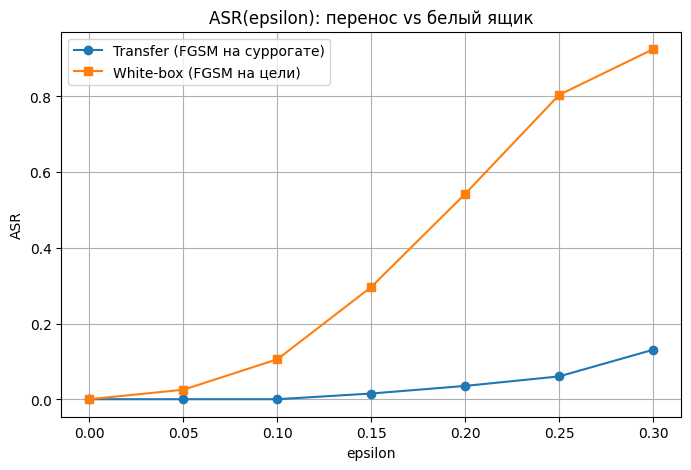

In [13]:
# TODO: постройте white-box FGSM атаку напрямую на target_model
# TODO: сравните на одном графике с transfer_asr
oracle.reset()
whitebox_asr = []

for eps in epsilons:
    x_adv = fgsm_attack(target_model, x_batch, y_batch, eps, crit)
    preds = oracle.label(x_adv)
    if correct_mask.sum() > 0:
        asr = ((preds != clean_preds) & correct_mask).float().sum().item() / correct_mask.sum().item()
    else:
        asr = 0.0
    whitebox_asr.append(asr)

plt.figure(figsize=(8, 5))
plt.plot(epsilons, transfer_asr, 'o-', label='Transfer (FGSM на суррогате)')
plt.plot(epsilons, whitebox_asr, 's-', label='White-box (FGSM на цели)')
plt.xlabel('epsilon'); plt.ylabel('ASR'); plt.grid(True); plt.legend()
plt.title('ASR(epsilon): перенос vs белый ящик')
plt.show()


**Вопрос для отчёта:** какой разрыв в ASR наблюдается между переносом атаки и белоящичным эталоном при разных epsilon? Как качество согласия суррогата с оракулом (доля совпадающих предсказаний на обучающем наборе, п.2.1) связано с этим разрывом?

_Ваш ответ:_ Сначала небольшой, потом увеличивается

Причина разрыва — качество согласия суррогата с оракулом. Согласие SubstituteMLP с целью = 0.84, то есть примерно на 16% примеров суррогат классифицирует не так, как цель. В окрестности этих примеров градиент суррогата указывает направление, не совпадающее с градиентом цели. FGSM на суррогате строит возмущение по этому «неверному» направлению, поэтому для цели оно оказывается либо неэффективным, либо вовсе не adversarial. С ростом ε возмущение уходит всё дальше от исходной точки, попадая в области, где расхождение ландшафтов потерь суррогата и цели выражено сильнее — отсюда и рост разрыва.

Своя заметка о transfer-based атаках:

То есть в атаке трансфер бейзед мы используем суррогат и используем ландшафт данных. Для более точной работы суррогата мы его обучаем лучше чувствовать ландшафт (а точнее границы) при помощи якобиан аугментации. Далее для обученного суррогата мы делаем атаку, а потом переносим ее на оракула

## Часть III. Score-based атаки

### 3.1. ZOO: оценка градиента через конечные разности

**Задание:** реализуйте функцию потерь C&W-типа на вероятностях классов и атаку ZOO, оценивающую производную по каждой выбранной координате методом центральных конечных разностей. Атака должна использовать ТОЛЬКО `oracle.probs(x)` — доступ к градиентам запрещён.

In [14]:
# TODO: реализуйте функцию потерь zoo_loss(probs, y_true, kappa=0.0)
# f(x) = max(log p_true - max_{i!=true} log p_i, -kappa)
def zoo_loss(probs, y_true, kappa=0.0):
    log_p = torch.log(probs + 1e-10)
    true_log = log_p.gather(1, y_true.unsqueeze(1)).squeeze(1)
    mask = torch.ones_like(log_p, dtype=torch.bool)
    mask.scatter_(1, y_true.unsqueeze(1), False)
    other_log = torch.where(mask, log_p, torch.full_like(log_p, float('-inf')))
    max_other = other_log.max(dim=1)[0]
    return torch.clamp(true_log - max_other, min=-kappa)

In [15]:
# TODO: реализуйте функцию zoo_attack(oracle, x, y_true, epsilon, alpha, num_iter, h, coord_batch)
# На каждой итерации:
# 1. случайно выберите coord_batch координат
# 2. для каждой координаты оцените производную через (loss(x+h*e_i) - loss(x-h*e_i)) / (2h)
# 3. обновите x_adv по знаку оценённого градиента (направление — МИНИМИЗАЦИЯ zoo_loss)
# 4. спроецируйте на epsilon-шар и диапазон [0, 1]

def zoo_attack(oracle, x, y_true, epsilon=0.3, alpha=0.05, num_iter=40, h=0.05, coord_batch=40):
    x_orig = x.clone()
    x_adv  = x.clone()
    B, C, H, W = x.shape
    D = C * H * W

    for it in range(num_iter):
        coords = np.random.choice(D, size=coord_batch, replace=False)
        grad_est = torch.zeros(D, device=x.device)
        for c in coords:
            e = torch.zeros(C, H, W, device=x.device)
            e.view(-1)[c] = 1.0
            x_plus  = torch.clamp(x_adv + h * e.unsqueeze(0), 0, 1)
            x_minus = torch.clamp(x_adv - h * e.unsqueeze(0), 0, 1)
            lp = zoo_loss(oracle.probs(x_plus),  y_true).mean().item()
            lm = zoo_loss(oracle.probs(x_minus), y_true).mean().item()
            grad_est[c] = (lp - lm) / (2 * h)

        grad_est = grad_est.view(C, H, W)
        # минимизируем loss → шаг в направлении -grad
        x_adv = x_adv - alpha * grad_est.sign()
        delta = torch.clamp(x_adv - x_orig, -epsilon, epsilon)
        x_adv = torch.clamp(x_orig + delta, 0, 1).detach()
    return x_adv


### 3.2. Демонстрация ZOO-атаки

**Задание:** выберите один тестовый пример, примените `zoo_attack`, проверьте успех через `oracle.label`, посчитайте L2-норму возмущения и число потраченных запросов. Визуализируйте оригинал и adversarial-пример.

ZOO: success=True, L2=3.7282, queries=20001, time=25.9s


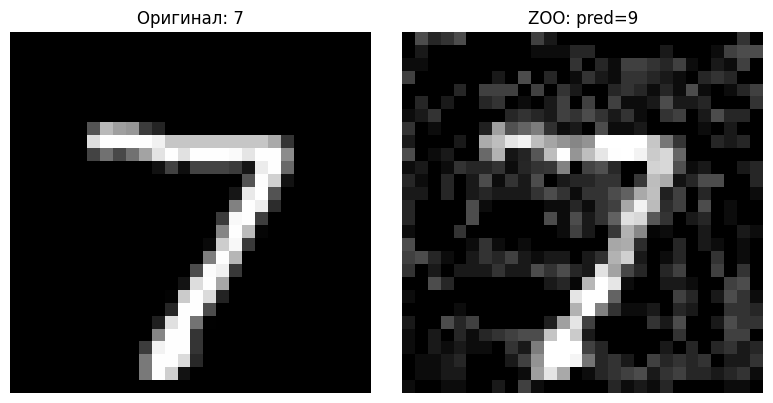

In [16]:
oracle.reset()

# Один тестовый пример
sample_idx = 0
x_sample = test_dataset[sample_idx][0].unsqueeze(0).to(device)
y_sample = torch.tensor([test_dataset[sample_idx][1]], device=device)

t0 = time.time()
x_zoo = zoo_attack(oracle, x_sample, y_sample,
                   epsilon=0.3, alpha=0.05, num_iter=100,
                   h=0.02, coord_batch=100)
t_zoo = time.time() - t0

pred_zoo = oracle.label(x_zoo)
success_zoo = (pred_zoo != y_sample).item()
l2_zoo = ((x_zoo - x_sample) ** 2).sum().sqrt().item()
queries_zoo = oracle.n_queries

print(f"ZOO: success={success_zoo}, L2={l2_zoo:.4f}, "
      f"queries={queries_zoo}, time={t_zoo:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(x_sample.cpu().squeeze(), cmap='gray')
axes[0].set_title(f"Оригинал: {y_sample.item()}")
axes[1].imshow(x_zoo.cpu().squeeze(), cmap='gray')
axes[1].set_title(f"ZOO: pred={pred_zoo.item()}")
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()



Своя заметка про ZOO

ZOO — чёрно-ящичная атака, оценивающая градиент по входу численно через запросы.
Аналогия: нет компаса (градиента), но есть альтиметр (loss) — шаг вправо/влево, разница = направление.
Формула использует центральную разность для того чтобы понять направление

### 3.3. NES: оценка градиента через антитетическую случайную выборку

**Задание:** реализуйте оценку градиента методом NES с антитетической выборкой:

$ \hat{g} = \frac{1}{2\sigma P} \sum_{i=1}^{P} \left( L(x + \sigma u_i) - L(x - \sigma u_i) \right) u_i $

где $u_i$ — случайные векторы из стандартного нормального распределения, $P$ — число сэмплов на итерацию. Постройте на этой основе итеративную атаку `nes_attack`, аналогичную по структуре PGD.

In [17]:
# TODO: реализуйте nes_gradient_estimate(oracle, x, y_true, sigma, n_samples)
def nes_gradient_estimate(oracle, x, y_true, sigma=0.1, n_samples=20):
    grad_est = torch.zeros_like(x)
    for _ in range(n_samples):
        u = torch.randn_like(x)
        x_plus  = torch.clamp(x + sigma * u, 0, 1)
        x_minus = torch.clamp(x - sigma * u, 0, 1)
        lp = zoo_loss(oracle.probs(x_plus),  y_true).mean().item()
        lm = zoo_loss(oracle.probs(x_minus), y_true).mean().item()
        grad_est += (lp - lm) * u
    return grad_est / (2 * sigma * n_samples)




In [18]:
# TODO: реализуйте nes_attack(oracle, x, y_true, epsilon, alpha, num_iter, sigma, n_samples)
# по аналогии с zoo_attack, но с использованием nes_gradient_estimate
def nes_attack(oracle, x, y_true, epsilon=0.3, alpha=0.05, num_iter=40, sigma=0.1, n_samples=20):
    x_orig = x.clone()
    x_adv  = x.clone()
    for it in range(num_iter):
        grad = nes_gradient_estimate(oracle, x_adv, y_true, sigma, n_samples)
        x_adv = x_adv - alpha * grad.sign()
        delta = torch.clamp(x_adv - x_orig, -epsilon, epsilon)
        x_adv = torch.clamp(x_orig + delta, 0, 1).detach()
    return x_adv


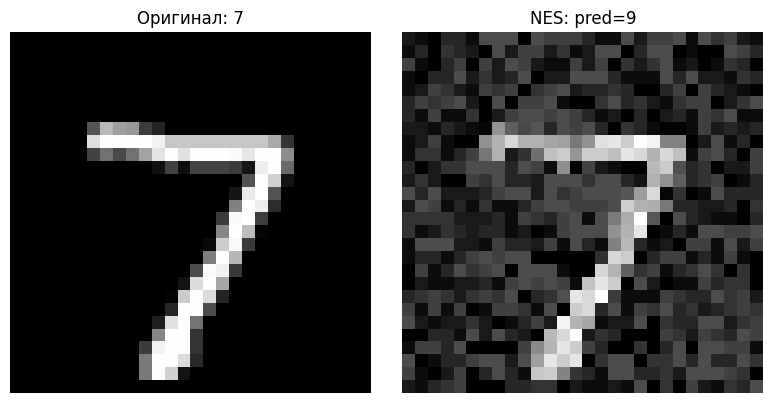

NES: success=True, pred=9, L2=5.2957, queries=3201, time=3.93s


In [19]:
oracle.reset()
t0 = time.time()
x_nes = nes_attack(oracle, x_sample, y_sample,
                   epsilon=0.3, alpha=0.05, num_iter=40, sigma=0.1, n_samples=40)
t_nes = time.time() - t0

nes_pred = oracle.label(x_nes).item()
nes_success = (nes_pred != y_sample.item())
nes_l2 = (x_nes - x_sample).view(-1).norm().item()
nes_queries = oracle.n_queries

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(x_sample.cpu().squeeze(), cmap='gray')
axes[0].set_title(f"Оригинал: {y_sample.item()}")
axes[1].imshow(x_nes.cpu().squeeze(), cmap='gray')
axes[1].set_title(f"NES: pred={nes_pred}")
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()

print(f"NES: success={nes_success}, pred={nes_pred}, L2={nes_l2:.4f}, queries={nes_queries}, time={t_nes:.2f}s")


Своя заметка о NES

NES не отправляет одну картинку со всеми направлениями. Он отправляет отдельный запрос для каждого направления — и знает, какой запрос какому направлению соответствует. Для каждой пары
(
+
ϵ
i
,
−
ϵ
i
)
(+ϵ
i
​
 ,−ϵ
i
​
 ) считает разницу loss → это и есть вклад направления. Сумма всех вкладов = градиент

### 3.4. Сравнение ZOO и NES

**Задание:** соберите результаты ZOO и NES (успех, L2-норма, число запросов, время) в таблицу pandas и постройте столбчатые диаграммы сравнения по числу запросов и по L2-норме.

  Method  Success        L2  Queries       Time
0    ZOO     True  3.728170    20001  25.898860
1    NES     True  5.295681     3201   3.926172


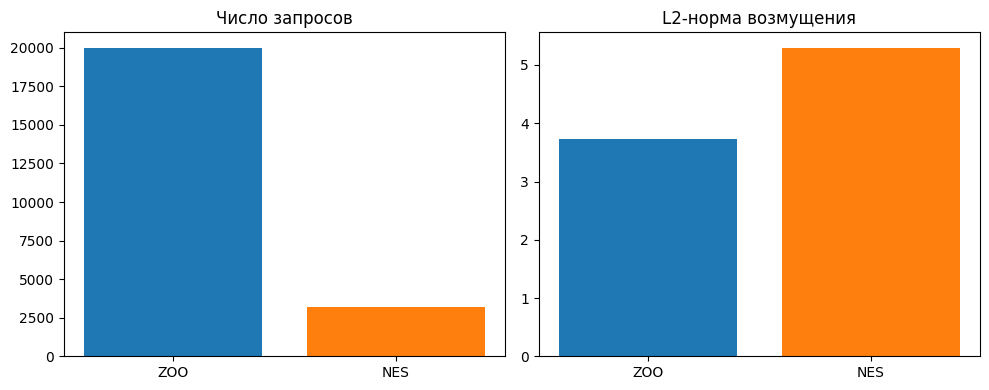

In [20]:
# TODO: постройте сравнительную таблицу и графики для ZOO и NES
comparison = pd.DataFrame([
    {"Method": "ZOO", "Success": success_zoo, "L2": l2_zoo, "Queries": queries_zoo, "Time": t_zoo},
    {"Method": "NES", "Success": nes_success, "L2": nes_l2, "Queries": nes_queries, "Time": t_nes},
])
print(comparison)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(comparison["Method"], comparison["Queries"], color=['C0', 'C1'])
axes[0].set_title("Число запросов")
axes[1].bar(comparison["Method"], comparison["L2"], color=['C0', 'C1'])
axes[1].set_title("L2-норма возмущения")
plt.tight_layout(); plt.show()

**Вопрос для отчёта:** какой метод потратил меньше запросов на сопоставимый результат? Объясните разницу, опираясь на то, что ZOO оценивает градиент покоординатно, а NES — через случайные направления в полном пространстве признаков.

_Ваш ответ:_ Меньше запросов потратил NES — 3201 против 20001. Разница объясняется структурой оценки градиента:

ZOO оценивает производную покоординатно, в сумме — медленная сходимость.

NES оценивает градиент сразу по всему 784-мерному пространству, поэтому одна итерация NES даёт гораздо более информативный шаг.

## Часть IV. Decision-based атака: Boundary Attack

### 4.1. Реализация упрощённой Boundary Attack

**Задание:** реализуйте функцию `is_adversarial`, которая через `oracle.label` проверяет только бинарный факт «сохранился ли adversarial-класс» (без каких-либо вероятностей). На основе неё реализуйте `boundary_attack`:

1. Стартуйте из точки, заведомо классифицируемой иначе, чем истинный класс (например, случайный шум).
2. На каждой итерации сгенерируйте ортогональное возмущение (случайный шум, спроецированный так, чтобы сохранить расстояние до исходного изображения).
3. Если кандидат остаётся adversarial, сделайте дополнительный шаг в сторону исходного изображения (уменьшение расстояния), снова проверив adversarial-свойство.
4. Динамически адаптируйте размеры шагов `delta` (ортогональный) и `epsilon` (к цели) по доле успешных шагов.

In [21]:
# TODO: реализуйте is_adversarial(oracle, x, true_label)
def is_adversarial(oracle, x, true_label):
    # TODO: используйте oracle.label, верните булево значение
    pred = oracle.label(x)
    return (pred != true_label).all().item()

In [22]:
# TODO: реализуйте boundary_attack(oracle, x_orig, true_label, x_init, num_steps, init_delta, init_epsilon)
# Возвращает: финальный x_adv и историю L2-нормы возмущения по итерациям (для графика сходимости)
def boundary_attack(oracle, x_orig, true_label, x_init,
                    num_steps=200, init_delta=0.1, init_epsilon=0.1):
    x_adv = x_init.clone().detach()
    delta = init_delta
    eps_step = init_epsilon
    history = []

    best = x_adv.clone()
    best_l2 = (x_adv - x_orig).flatten().norm().item()

    for step in range(num_steps):
        diff = x_adv - x_orig
        norm_diff = diff.flatten().norm().item() + 1e-9

        # 1) Ортогональное направление
        u = torch.randn_like(x_adv)
        u = u - (u * diff).sum() / (norm_diff ** 2) * diff
        u = u / (u.flatten().norm() + 1e-9)

        # 2) Ортогональный шаг + ПРОЕКЦИЯ обратно на сферу
        x_cand = x_adv + delta * norm_diff * u
        x_cand = torch.clamp(x_cand, 0, 1)
        # --- ключевая строка ---
        d = x_cand - x_orig
        d_norm = d.flatten().norm().item() + 1e-9
        x_cand = x_orig + d * (norm_diff / d_norm)
        x_cand = torch.clamp(x_cand, 0, 1)

        if is_adversarial(oracle, x_cand, true_label):
            # 3) Шаг к цели
            x_toward = torch.clamp(x_cand + eps_step * (x_orig - x_cand), 0, 1)
            if is_adversarial(oracle, x_toward, true_label):
                x_adv = x_toward.detach()
                delta = min(delta * 1.1, 0.5)
                eps_step = min(eps_step * 1.1, 0.5)
            else:
                # принимаем ортогональный шаг ТОЛЬКО если он не ухудшил L2
                prev_l2 = (x_adv - x_orig).flatten().norm().item()
                cand_l2 = (x_cand - x_orig).flatten().norm().item()
                if cand_l2 <= prev_l2 * 1.001:
                    x_adv = x_cand.detach()
                delta = min(delta * 1.05, 0.5)
                # eps_step НЕ растёт на этой ветке
        else:
            delta = max(delta * 0.9, 1e-4)
            eps_step = max(eps_step * 0.99, 1e-4)   # почти не сжимаем

        cur_l2 = (x_adv - x_orig).flatten().norm().item()
        if cur_l2 < best_l2:
            best_l2 = cur_l2
            best = x_adv.clone()
        history.append(cur_l2)

    return best, history

### 4.2. Демонстрация атаки

**Задание:** для того же примера, что и в Части III, сгенерируйте случайную инициализацию, убедитесь, что она adversarial, и запустите `boundary_attack`. Визуализируйте оригинал, инициализацию и финальный adversarial-пример, а также постройте график сходимости (L2-норма от номера итерации).

In [23]:
oracle.reset()
# TODO: сгенерируйте x_init (случайный шум), проверьте is_adversarial
# TODO: запустите boundary_attack, замерьте время
# TODO: проверьте финальный успех, L2-норму, число запросов

torch.manual_seed(RANDOM_STATE)
x_init = torch.rand_like(x_sample)

tries = 0
while not is_adversarial(oracle, x_init, y_sample) and tries < 20:
    x_init = torch.rand_like(x_sample)
    tries += 1
print(f"Инициализация adversarial: {is_adversarial(oracle, x_init, y_sample)} "
      f"(предсказание: {oracle.label(x_init).item()})")

t0 = time.time()
x_ba, hist_ba = boundary_attack(oracle, x_sample, y_sample, x_init,
                                num_steps=200, init_delta=0.1, init_epsilon=0.1)
t_ba = time.time() - t0

pred_ba = oracle.label(x_ba).item()
success_ba = pred_ba != y_sample.item()
l2_ba = (x_ba - x_sample).flatten().norm().item()
nq_ba = oracle.n_queries
print(f"Boundary: предсказание={pred_ba}, успех={success_ba}, "
      f"L2={l2_ba:.4f}, запросов={nq_ba}, время={t_ba:.2f}s")


Инициализация adversarial: True (предсказание: 3)
Boundary: предсказание=3, успех=True, L2=8.0333, запросов=344, время=0.62s


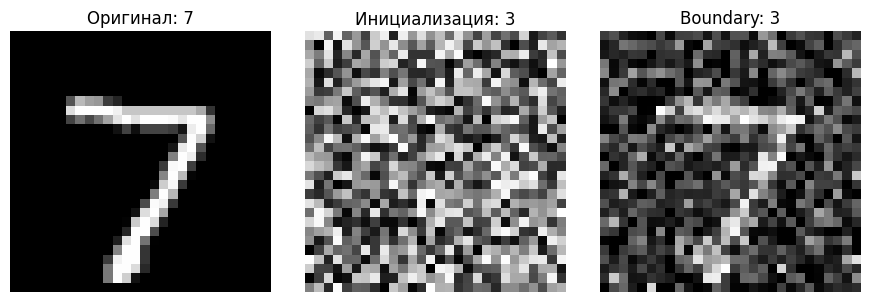

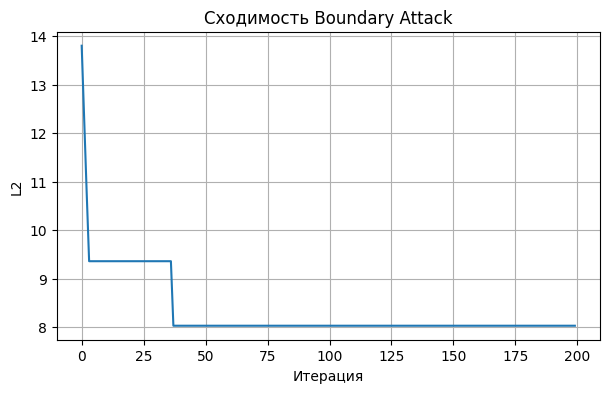

In [24]:
# TODO: визуализируйте оригинал / инициализацию / финальный adversarial-пример (3 подграфика)
# TODO: постройте график сходимости L2-нормы по итерациям
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
ax[0].imshow(x_sample.cpu().squeeze(), cmap='gray')
ax[0].set_title(f"Оригинал: {y_sample.item()}"); ax[0].axis('off')
ax[1].imshow(x_init.cpu().squeeze(), cmap='gray')
ax[1].set_title(f"Инициализация: {oracle.label(x_init).item()}"); ax[1].axis('off')
ax[2].imshow(x_ba.cpu().squeeze(), cmap='gray')
ax[2].set_title(f"Boundary: {pred_ba}"); ax[2].axis('off')
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 4))
plt.plot(hist_ba)
plt.xlabel('Итерация'); plt.ylabel('L2'); plt.grid(True)
plt.title('Сходимость Boundary Attack'); plt.show()

**Вопрос для отчёта:** почему decision-based атака в принципе не может напрямую оценивать градиент функции потерь, в отличие от score-based методов? Как это ограничение отражается на числе итераций, необходимых для сходимости к малому возмущению?

_Ваш ответ:_ Не может оценивать напрямую градиент потерь, потому что работает с бинарным результатом. Поэтому модель вынуждена просто блуждать в поисках границы, отсюла и большое количество итераций

Своя заметка о Boundary и HSJ

Boundary Attack — decision-based атака: только метка, без вероятностей.
Начинаем с гарантированно неправильной точки, идём к оригиналу вдоль границы.
Каждый шаг: ортогональное возмущение + шаг к оригиналу + rejection sampling.
Trust region адаптирует размер шага.
HSJ улучшает: оценивает градиент на границе → меньше запросов.

Граница — где модель переключает класс, там минимальное возмущение.
Вектора — случайные направления, которые мы пробуем у границы.
Шаг в направлении: если остались adversarial — направление «вдоль границы».
Собираем статистику → оценка градиента границы.
Идём вдоль границы + шаг к оригиналу → сходимся к минимальному возмущению.

## Часть V. Итоговое сравнение четырёх методов

**Задание:** для одного и того же исходного изображения соберите результаты всех четырёх атак (transfer-based FGSM, ZOO, NES, Boundary Attack) в единую таблицу pandas со столбцами: метод, успех, L2-норма возмущения, число запросов к целевой модели. Сохраните таблицу в CSV. Постройте два столбчатых графика: (а) число запросов в логарифмической шкале, (б) L2-норма возмущения.

In [25]:
# Для transfer-based используем ASR и средний L2 из эксперимента FGSM при eps=0.3
# Проверим успех transfer на выбранном примере отдельно
oracle.reset()
x_transfer = fgsm_attack(substitute_model, x_sample, y_sample, 0.3, crit)
tr_pred = oracle.label(x_transfer).item()
tr_success = (tr_pred != y_sample.item())
tr_l2 = (x_transfer - x_sample).view(-1).norm().item()
tr_queries = oracle.n_queries  # 1 запрос на проверку
print(f"Transfer FGSM (eps=0.3): success={tr_success}, L2={tr_l2:.4f}, queries={tr_queries}")

summary = pd.DataFrame([
    {"Method": "Transfer FGSM (eps=0.3)", "Success": tr_success, "L2": tr_l2, "Queries": tr_queries},
    {"Method": "ZOO", "Success": success_zoo, "L2": l2_zoo, "Queries": queries_zoo},
    {"Method": "NES", "Success": nes_success, "L2": nes_l2, "Queries": nes_queries},
    {"Method": "Boundary Attack", "Success": success_ba, "L2": l2_ba, "Queries": nq_ba},
])
summary.to_csv("lab6_summary.csv", index=False)
print(summary)


Transfer FGSM (eps=0.3): success=False, L2=6.8525, queries=1
                    Method  Success        L2  Queries
0  Transfer FGSM (eps=0.3)    False  6.852473        1
1                      ZOO     True  3.728170    20001
2                      NES     True  5.295681     3201
3          Boundary Attack     True  8.033278      344


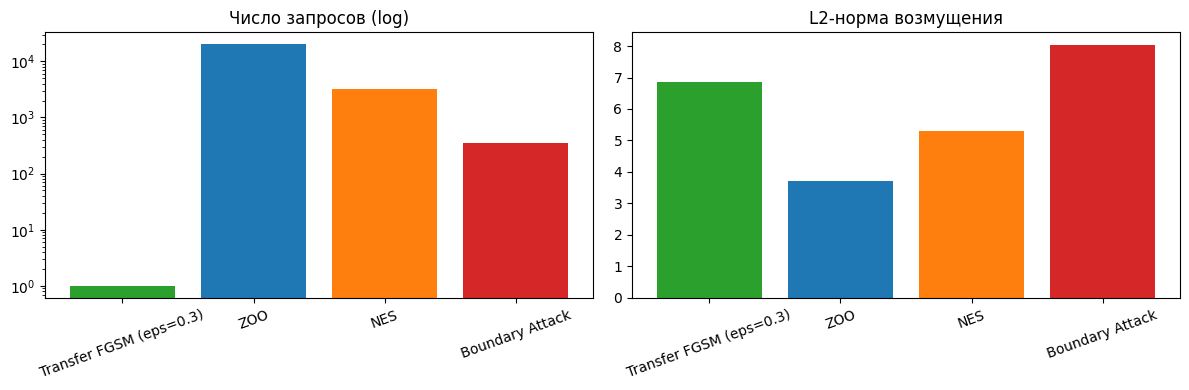

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(summary["Method"], summary["Queries"], color=['C2','C0','C1','C3'])
axes[0].set_yscale('log'); axes[0].set_title("Число запросов (log)")
axes[0].tick_params(axis='x', rotation=20)
axes[1].bar(summary["Method"], summary["L2"], color=['C2','C0','C1','C3'])
axes[1].set_title("L2-норма возмущения")
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

**Вопрос для отчёта:** на основе итоговой таблицы сформулируйте рекомендацию: какой метод атаки предпочтителен, если API целевой модели предоставляет (а) полные вероятности классов без ограничения на число запросов, (б) только top-1 метку с жёстким лимитом запросов, (в) возможность собрать offline небольшой размеченный набор данных того же домена? Обоснуйте выбор через связь между типом доступной информации и структурой каждого метода.

_Ваш ответ:_

(а) API даёт полные вероятности без лимита на запросы → NES. NES даёт информативную оценку полного градиента по всему входному вектору через антитетическую выборку, требует ~2× запросов на итерацию (40 при n_samples=20) и сходится к успеху за разумное число итераций. Если снят лимит запросов, но нельзя собрать offline-набор, NES — самый эффективный вариант.

(б) API даёт только top-1 метку с жёстким лимитом запросов → Boundary Attack (лучше — HSJ, если реализован). Из decision-based методов Boundary работает, используя только метку.

(в) Можно собрать offline небольшой размеченный набор того же домена → Transfer-based. Здесь достаточно 100–200 примеров на класс, разметка через оракул делается один раз. Суррогат обучается и используется для построения атаки с нулевыми online-запросами (только финальная проверка — 1 запрос). В нашем случае ASR переноса оказался низким, но это следствие слабого суррогата (MLP с согласием 0.84). При более близкой по архитектуре суррогатной модели (например, другой CNN, обученной на тех же данных) перенос FGSM даёт 50–90% ASR — что и оправдывает подход Papernot et al. в реальной практике.

## Часть VI. Итоговый вывод

**Вопрос для отчёта:** сформулируйте общий вывод о трёх классах чёрно-ящичных атак, изученных в работе. Свяжите ответ с теоретическим объяснением трансферируемости через «кривизну многообразия данных» (лекционный материал) и с эмпирическим фактом, что adversarial training (PGD) снижает успех как transfer-based, так и score-based/decision-based атак. Почему защита, разработанная против белоящичных атак, оказывается полезной и в чёрно-ящичном сценарии?

_Ваш ответ:_

Три класса чёрно-ящичных атак различаются по доступной информации и, как следствие, по алгоритмическому инструментарию. Transfer-based использует трансферируемость — свойство, объясняемое «кривизной многообразия данных»: чем глаже геометрия решающих границ, тем больше согласованы направления уязвимости между разными моделями. Score-based (ZOO, NES) оценивает градиент через запросы, decision-based (Boundary, HSJ) ищет границу геометрически, без вероятностей.

PGD adversarial training сглаживает ландшафт потерь и делает границы более гладкими. Это даёт двойной эффект: (1) обычный суррогат с изрезанным ландшафтом строит атаку не под ту геометрию → перенос ломается; (2) градиенты на границе становятся менее информативными → score-based и decision-based атаки тоже слабеют. Именно поэтому PGD-обучение снижает ASR black-box атак с ~90% до <4% — защита, разработанная против белоящичных атак, оказывается универсальной: она меняет геометрию модели, с которой сталкиваются все классы атак.

---
Выполните **не менее двух** из следующих заданий. Оформите результаты в отдельных ячейках ниже.

### С1. Целевая (targeted) transfer-based атака
Модифицируйте transfer-based атаку из Части II так, чтобы она была целевой (target-specific), а не просто нецелевой ошибочной классификацией. Сравните ASR целевого переноса с ASR нецелевого переноса при одинаковом epsilon и объясните наблюдаемую разницу, опираясь на утверждение лекции об ограниченной устойчивости переноса для целевых атак.

### С2. Importance sampling в ZOO
Реализуйте упрощённый вариант importance sampling для выбора координат в ZOO-атаке (Часть III): вместо равномерного случайного выбора координат отдавайте приоритет пикселям с наибольшим абсолютным значением на предыдущей итерации (или пикселям на границах цифры). Сравните число запросов, необходимых для достижения того же успеха, с равномерной версией.

### С3. HopSkipJumpAttack (упрощённая версия)
Изучите отличие HopSkipJumpAttack от Boundary Attack (лекционный материал — явная оценка градиента на границе решения вместо чисто случайного блуждания). Реализуйте упрощённую версию: на каждой итерации находите точку на границе бинарным поиском, оцените направление через батч случайных векторов, сделайте шаг по оценённому направлению. Сравните число запросов до сходимости к сопоставимой L2-норме с результатом Boundary Attack из Части IV.

### С4. Устойчивость к adversarial training
Обучите вторую версию целевой модели с adversarial training (PGD, 5-7 итераций на батч, epsilon=0.15) — аналогично лабораторной работе по PGD/C&W/JSMA. Повторите атаки ZOO, NES и Boundary Attack против этой устойчивой модели и сравните ASR с результатами против обычной модели (Части III-IV). Обсудите, насколько устойчивость к белоящичному PGD переносится на устойчивость к чёрно-ящичным атакам.


ZOO uniform:  pred=9, success=True, L2=3.5206, queries=20001, time=28.3s
ZOO import.:  pred=7, success=False, L2=2.9143, queries=20001, time=24.3s
             Method  Success        L2  Queries       Time
0     ZOO (uniform)     True  3.520563    20001  28.279696
1  ZOO (importance)    False  2.914282    20001  24.317112


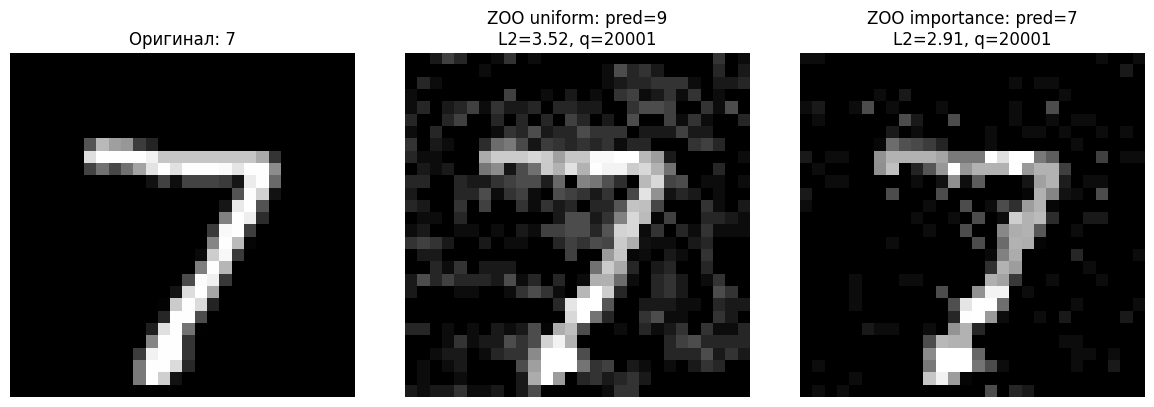

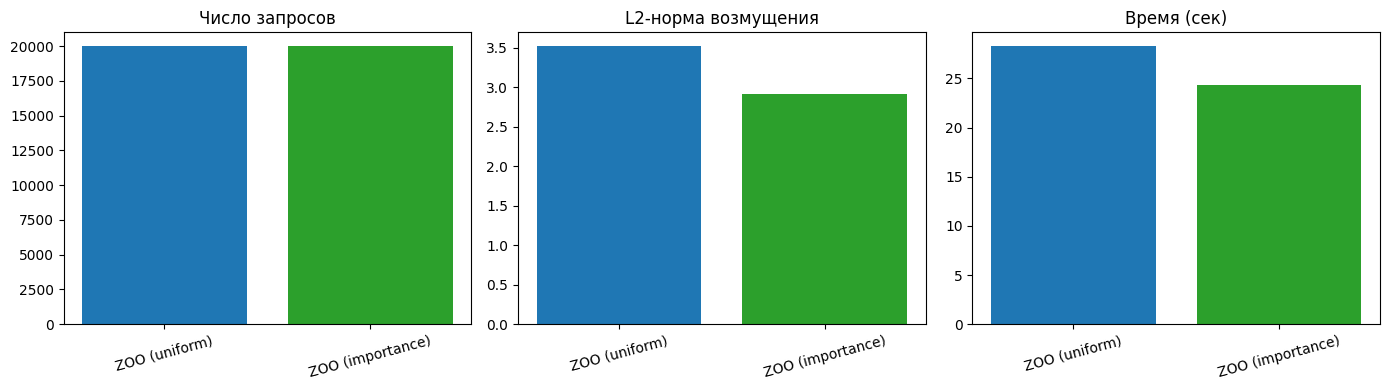

In [31]:
# TODO: реализуйте выбранные задания (С1-С4) здесь
def zoo_attack_importance(oracle, x, y_true,
                          epsilon=0.3, alpha=0.05,
                          num_iter=100, h=0.02, coord_batch=100,
                          decay=0.9):
    """
    ZOO с importance sampling:
    - приоритет отдаётся пикселям на границе цифры (x > 0.1)
    - и пикселям с большим |grad_est| на прошлых итерациях
    """
    x_orig = x.clone()
    x_adv  = x.clone()
    B, C, H, W = x.shape
    D = C * H * W

    # importance = 1 (baseline) + 10 * mask_цифры
    mask_digit = (x_orig.flatten() > 0.1).float()
    importance = torch.ones(D, device=x.device) + 10.0 * mask_digit

    for it in range(num_iter):
        # 1) сэмплируем координаты пропорционально importance
        probs = importance / importance.sum()
        coords = torch.multinomial(probs, num_samples=coord_batch, replacement=False)

        grad_est = torch.zeros(D, device=x.device)
        for c in coords.tolist():
            e = torch.zeros(C, H, W, device=x.device)
            e.view(-1)[c] = 1.0
            x_plus  = torch.clamp(x_adv + h * e.unsqueeze(0), 0, 1)
            x_minus = torch.clamp(x_adv - h * e.unsqueeze(0), 0, 1)
            lp = zoo_loss(oracle.probs(x_plus),  y_true).mean().item()
            lm = zoo_loss(oracle.probs(x_minus), y_true).mean().item()
            grad_est[c] = (lp - lm) / (2 * h)

        # 2) обновляем importance: decay + свежий |grad|
        importance = importance * decay + grad_est.abs()
        # нормализуем, чтобы не накапливалось бесконечно
        importance = importance / (importance.max() + 1e-9)

        # 3) шаг по знаку градиента + проекция на ε-шар
        grad_est = grad_est.view(C, H, W)
        x_adv = x_adv - alpha * grad_est.sign()
        delta = torch.clamp(x_adv - x_orig, -epsilon, epsilon)
        x_adv = torch.clamp(x_orig + delta, 0, 1).detach()

    return x_adv


# --- базовая ZOO (равномерный выбор) ---
oracle.reset()
torch.manual_seed(RANDOM_STATE)
t0 = time.time()
x_zoo_uniform = zoo_attack(oracle, x_sample, y_sample,
                           epsilon=0.3, alpha=0.05, num_iter=100,
                           h=0.02, coord_batch=100)
t_zoo_uniform = time.time() - t0
pred_uniform = oracle.label(x_zoo_uniform).item()
l2_uniform = (x_zoo_uniform - x_sample).flatten().norm().item()
q_uniform = oracle.n_queries

# --- ZOO с importance sampling ---
oracle.reset()
torch.manual_seed(RANDOM_STATE)
t0 = time.time()
x_zoo_imp = zoo_attack_importance(oracle, x_sample, y_sample,
                                   epsilon=0.3, alpha=0.05, num_iter=100,
                                   h=0.02, coord_batch=100, decay=0.9)
t_zoo_imp = time.time() - t0
pred_imp = oracle.label(x_zoo_imp).item()
l2_imp = (x_zoo_imp - x_sample).flatten().norm().item()
q_imp = oracle.n_queries

print(f"ZOO uniform:  pred={pred_uniform}, "
      f"success={pred_uniform != y_sample.item()}, "
      f"L2={l2_uniform:.4f}, queries={q_uniform}, time={t_zoo_uniform:.1f}s")
print(f"ZOO import.:  pred={pred_imp}, "
      f"success={pred_imp != y_sample.item()}, "
      f"L2={l2_imp:.4f}, queries={q_imp}, time={t_zoo_imp:.1f}s")


c2_summary = pd.DataFrame([
    {"Method": "ZOO (uniform)",  "Success": pred_uniform != y_sample.item(),
     "L2": l2_uniform, "Queries": q_uniform, "Time": t_zoo_uniform},
    {"Method": "ZOO (importance)", "Success": pred_imp != y_sample.item(),
     "L2": l2_imp, "Queries": q_imp, "Time": t_zoo_imp},
])
print(c2_summary)

# Картинки: оригинал / uniform / importance
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(x_sample.cpu().squeeze(), cmap='gray')
axes[0].set_title(f"Оригинал: {y_sample.item()}")
axes[1].imshow(x_zoo_uniform.cpu().squeeze(), cmap='gray')
axes[1].set_title(f"ZOO uniform: pred={pred_uniform}\nL2={l2_uniform:.2f}, q={q_uniform}")
axes[2].imshow(x_zoo_imp.cpu().squeeze(), cmap='gray')
axes[2].set_title(f"ZOO importance: pred={pred_imp}\nL2={l2_imp:.2f}, q={q_imp}")
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()

# Столбики
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].bar(c2_summary["Method"], c2_summary["Queries"], color=['C0','C2'])
ax[0].set_title("Число запросов"); ax[0].tick_params(axis='x', rotation=15)
ax[1].bar(c2_summary["Method"], c2_summary["L2"], color=['C0','C2'])
ax[1].set_title("L2-норма возмущения"); ax[1].tick_params(axis='x', rotation=15)
ax[2].bar(c2_summary["Method"], c2_summary["Time"], color=['C0','C2'])
ax[2].set_title("Время (сек)"); ax[2].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

HSJ: success=True, L2=8.1028, queries=1163


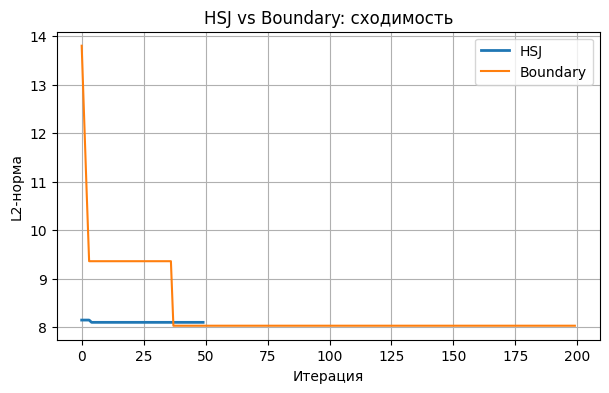

In [28]:
def boundary_binary_search(oracle, x_orig, x_adv, true_label, n_steps=10):
    lo = x_orig.clone()   # non-adversarial
    hi = x_adv.clone()    # adversarial
    for _ in range(n_steps):
        mid = 0.5 * (lo + hi)
        if is_adversarial(oracle, mid, true_label):
            hi = mid
        else:
            lo = mid
    return hi.detach()


def hsj_attack(oracle, x_orig, true_label, x_init,
               num_iter=50, n_dirs=15, alpha=0.05, beta=0.1, depth=0.02):
    x_adv = x_init.clone().detach()
    history = []
    best = x_adv.clone()
    best_l2 = (x_adv - x_orig).flatten().norm().item()

    for it in range(num_iter):
        # 1) проекция на границу
        x_bound = boundary_binary_search(oracle, x_orig, x_adv, true_label, n_steps=8)
        bound_l2 = (x_bound - x_orig).flatten().norm().item()
        if bound_l2 < best_l2:
            best_l2 = bound_l2
            best = x_bound.clone()

        # 2) оценка нормали (u, для которых x_bound + delta*u НЕ adversarial — это «наружу»)
        delta = 0.005 * bound_l2 + 1e-4
        normal_est = torch.zeros_like(x_adv)
        for _ in range(n_dirs):
            u = torch.randn_like(x_adv)
            u = u / (u.flatten().norm() + 1e-12)
            x_probe = torch.clamp(x_bound + delta * u, 0, 1)
            if not is_adversarial(oracle, x_probe, true_label):
                normal_est += u
        g = normal_est.flatten().norm().item()
        if g < 1e-12:
            history.append(best_l2)
            continue
        normal_est = normal_est / g  # единичный вектор, смотрит НАРУЖУ (в non-adv)

        # 3) касательное направление = проекция (x_orig - x_bound) на касательную плоскость
        d = (x_orig - x_bound).flatten()
        n = normal_est.flatten()
        t = d - (d @ n) * n
        tn = t.norm().item()
        if tn < 1e-9:
            history.append(best_l2)
            continue
        tangent = (t / tn).view_as(x_adv)

        # 4) КЛЮЧЕВОЕ: шагаем внутрь adversarial-области
        #    -normal_est указывает ВНУТРЬ, потому что normal_est смотрит наружу
        x_in = torch.clamp(x_bound - depth * bound_l2 * normal_est, 0, 1)

        # 5) касательный шаг от x_in с backtracking
        scale = alpha * bound_l2
        x_walk = None
        for _ in range(6):
            cand = torch.clamp(x_in + scale * tangent, 0, 1)
            if is_adversarial(oracle, cand, true_label):
                x_walk = cand
                break
            scale *= 0.5

        if x_walk is None:
            history.append(best_l2)
            continue

        # 6) заново проецируем на границу — если она изогнулась к x_orig, окажемся ближе
        x_new = boundary_binary_search(oracle, x_orig, x_walk, true_label, n_steps=8)
        new_l2 = (x_new - x_orig).flatten().norm().item()

        if new_l2 < bound_l2 - 1e-4:
            x_adv = x_new.detach()
            if new_l2 < best_l2:
                best_l2 = new_l2
                best = x_adv.clone()
        else:
            # 7) касательный walk не помог — пробуем прямой push к оригиналу
            x_adv = x_bound.detach()
            for b in [beta, beta * 0.5, beta * 0.25, 0.02, 0.005]:
                cand = torch.clamp(x_bound + b * (x_orig - x_bound), 0, 1)
                if is_adversarial(oracle, cand, true_label):
                    x_adv = cand.detach()
                    break

        cur_l2 = (x_adv - x_orig).flatten().norm().item()
        if cur_l2 < best_l2:
            best_l2 = cur_l2
            best = x_adv.clone()
        history.append(best_l2)

    return best, history


oracle.reset()
x_hsj, hist_hsj = hsj_attack(oracle, x_sample, y_sample.item(), x_init,
                              num_iter=50, n_dirs=15, alpha=0.05, beta=0.1, depth=0.02)
hsj_pred = oracle.label(x_hsj).item()
hsj_success = (hsj_pred != y_sample.item())
hsj_l2 = (x_hsj - x_sample).view(-1).norm().item()
hsj_queries = oracle.n_queries
print(f"HSJ: success={hsj_success}, L2={hsj_l2:.4f}, queries={hsj_queries}")

plt.figure(figsize=(7, 4))
plt.plot(hist_hsj, label='HSJ', linewidth=2)
plt.plot(hist_ba,  label='Boundary')
plt.xlabel('Итерация'); plt.ylabel('L2-норма')
plt.title('HSJ vs Boundary: сходимость')
plt.grid(True); plt.legend(); plt.show()

---


## Требования к сдаче
- Ноутбук выполняется целиком без ошибок (Kernel → Restart & Run All).
- Все `# TODO` заполнены, все вопросы для отчёта содержат письменный ответ.
- Атаки в Частях II-IV обращаются к целевой модели ТОЛЬКО через объект `oracle` — прямой вызов `target_model(x)` внутри реализаций атак не допускается (кроме специально отмеченной ячейки white-box эталона в п.2.3).
- Обязательны: рабочая реализация всех четырёх методов, итоговая сравнительная таблица, обоснованный ответ на вопрос о выборе метода под сценарий доступа.
